In [11]:
# STEP 3: EXPLORATORY DATA ANALYSIS (EDA)
# IMPORT LIBRARIES AND LOAD DATA

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

In [12]:
# DEFINE PROJECT PATHS

BASE_DIR = os.path.dirname(os.getcwd())
INPUT_PATH = os.path.join(BASE_DIR, "outputs", "cleaned_clinical_trials.csv")
CHARTS_PATH = os.path.join(BASE_DIR, "outputs", "eda_charts")

os.makedirs(CHARTS_PATH, exist_ok=True)

print("Input file:", INPUT_PATH)
print("Charts folder:", CHARTS_PATH)

Input file: c:\Users\acer\Documents\Clinical_Trial_Classification\outputs\cleaned_clinical_trials.csv
Charts folder: c:\Users\acer\Documents\Clinical_Trial_Classification\outputs\eda_charts


In [13]:
#Load Cleaned Dataset

df = pd.read_csv(INPUT_PATH)

print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (60337, 16)


In [14]:
#Display First 5 Rows

df.head()

,source_condition_query,nct_id,title,official_title,brief_summary,conditions,interventions,overall_status,study_type,phase,sex,minimum_age,maximum_age,healthy_volunteers,eligibility_criteria,clinicaltrials_url
0,breast cancer,NCT03676114,Effect of Perioperative Low Dose Ketamine on P...,Effect of Perioperative Low Dose Ketamine on P...,Breast cancer patients often have perioperativ...,Breast Cancer,ketamine | Normal saline,UNKNOWN,INTERVENTIONAL,PHASE4,FEMALE,20 Years,65 Years,False,Inclusion Criteria:\n\n1. American Society of ...,https://clinicaltrials.gov/study/NCT03676114
1,breast cancer,NCT02941614,Implementing Systematic Distress Screening in ...,Implementing Systematic Distress Screening in ...,Many breast cancer patients experience psychol...,Breast Cancer,Distress screening,COMPLETED,OBSERVATIONAL,NaN,ALL,18 Years,NaN,False,Inclusion Criteria:\n\n* Newly diagnosed with ...,https://clinicaltrials.gov/study/NCT02941614
2,breast cancer,NCT04509063,Investigating Public Enthusiasm for Mammograph...,Investigating Public Enthusiasm for Mammograph...,"Based on an American study by Scherer et al., ...",Breast Neoplasm Female | Mammography Screening...,Information about hypothetical mammography scr...,COMPLETED,INTERVENTIONAL,NaN,FEMALE,44 Years,49 Years,True,Inclusion Criteria:\n\n* Residence: Central De...,https://clinicaltrials.gov/study/NCT04509063
3,breast cancer,NCT04327063,MIRs 04 : Interpectoral Nerve Block With Ropiv...,A Double-blind Randomized Trial of Interpector...,Compare the effect of ropivacaine versus place...,Malignant Neoplasm of Breast,Saline | Ropivacaine,COMPLETED,INTERVENTIONAL,PHASE3,FEMALE,18 Years,85 Years,False,Inclusion Criteria:\n\n1. Women with non-metas...,https://clinicaltrials.gov/study/NCT04327063
4,breast cancer,NCT06778863,A Study of CLSP-1025 in Adult Patients With So...,GUARDIAN-101: A Phase 1 Dose Escalation and Ex...,Phase 1 dose escalation and expansion study of...,Advanced Solid Tumor | Unresectable Solid Tumo...,CLSP-1025,RECRUITING,INTERVENTIONAL,PHASE1,ALL,18 Years,NaN,False,Key Inclusion Criteria:\n\n* Patients must be ...,https://clinicaltrials.gov/study/NCT06778863


In [15]:
#Dataset Information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60337 entries, 0 to 60336
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   source_condition_query  60337 non-null  str   
 1   nct_id                  60337 non-null  str   
 2   title                   60337 non-null  str   
 3   official_title          59551 non-null  str   
 4   brief_summary           60337 non-null  str   
 5   conditions              60336 non-null  str   
 6   interventions           54276 non-null  str   
 7   overall_status          60337 non-null  str   
 8   study_type              60337 non-null  str   
 9   phase                   23336 non-null  str   
 10  sex                     60304 non-null  str   
 11  minimum_age             57121 non-null  str   
 12  maximum_age             28400 non-null  str   
 13  healthy_volunteers      58857 non-null  object
 14  eligibility_criteria    60326 non-null  str   
 15  clinicaltrial

In [16]:
#Check Missing Values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values[missing_values > 0].sort_values(ascending=False))

Missing Values in Each Column:
phase                   37001
maximum_age             31937
interventions            6061
minimum_age              3216
healthy_volunteers       1480
official_title            786
sex                        33
eligibility_criteria       11
conditions                  1
dtype: int64


In [17]:
# CHECK MISSING VALUES IN ALL COLUMNS

missing_values = df.isnull().sum().sort_values(ascending=False)

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
phase                     37001
maximum_age               31937
interventions              6061
minimum_age                3216
healthy_volunteers         1480
official_title              786
sex                          33
eligibility_criteria         11
conditions                    1
overall_status                0
nct_id                        0
title                         0
source_condition_query        0
brief_summary                 0
study_type                    0
clinicaltrials_url            0
dtype: int64


In [18]:
#Disease Category Distribution

category_counts = df["source_condition_query"].value_counts()

print("Number of Clinical Trials in Each Disease Category:")
print(category_counts)
print("\nTotal Disease Categories:", category_counts.shape[0])

Number of Clinical Trials in Each Disease Category:
source_condition_query
breast cancer                            16301
type 2 diabetes                          11467
covid-19                                 10153
anxiety                                   9286
chronic obstructive pulmonary disease     6181
rheumatoid arthritis                      3637
glaucoma                                  2173
sickle cell anemia                        1139
Name: count, dtype: int64

Total Disease Categories: 8


In [19]:
#Disease Category Percentages

category_percentages = (
    df["source_condition_query"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Disease Category Percentages:")
print(category_percentages)

Disease Category Percentages:
source_condition_query
breast cancer                            27.02
type 2 diabetes                          19.00
covid-19                                 16.83
anxiety                                  15.39
chronic obstructive pulmonary disease    10.24
rheumatoid arthritis                      6.03
glaucoma                                  3.60
sickle cell anemia                        1.89
Name: proportion, dtype: float64


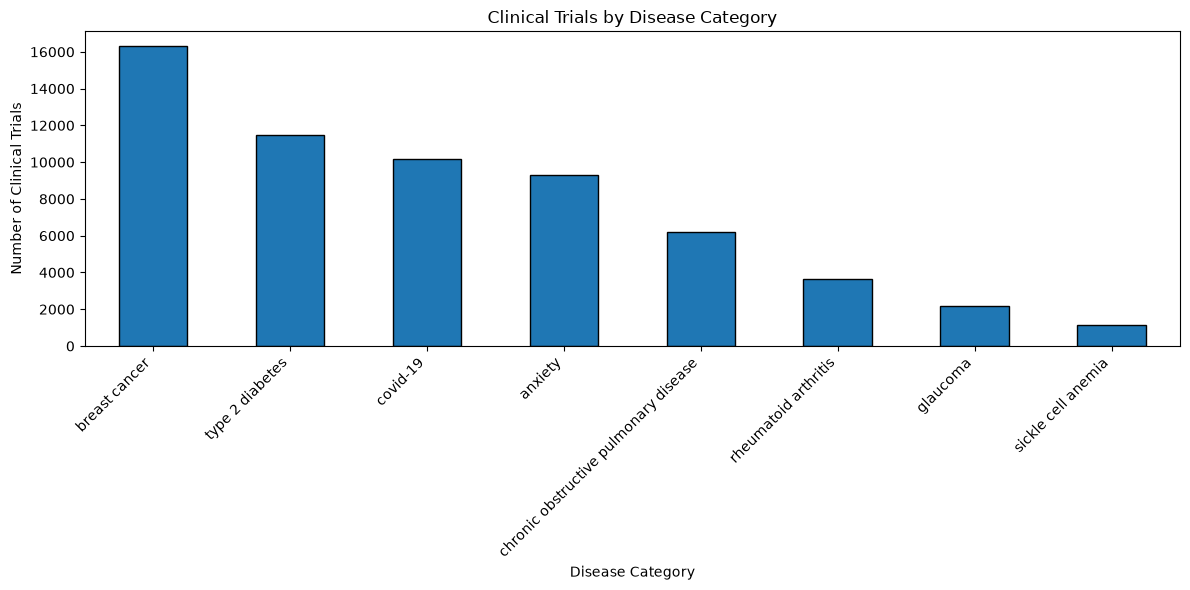

In [20]:
#Disease Category Distribution Chart

plt.figure(figsize=(12, 6))

category_counts.sort_values(ascending=False).plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Clinical Trials by Disease Category")
plt.xlabel("Disease Category")
plt.ylabel("Number of Clinical Trials")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(CHARTS_PATH, "disease_category_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
#Brief Summary Text Length Analysis

df["summary_length"] = df["brief_summary"].str.len()

print("Summary Length Statistics:")
print(df["summary_length"].describe())

Summary Length Statistics:
count    60337.000000
mean       688.297396
std        630.584628
min         17.000000
25%        253.000000
50%        466.000000
75%        904.000000
max       5011.000000
Name: summary_length, dtype: float64


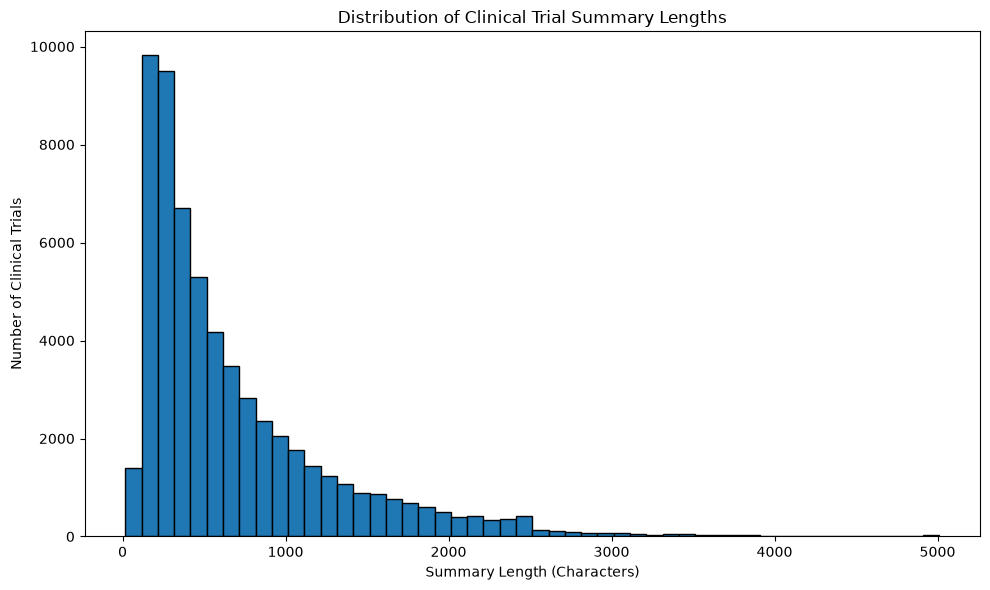

In [22]:
#Brief Summary Length Distribution Chart

plt.figure(figsize=(10, 6))

plt.hist(df["summary_length"], bins=50, edgecolor="black")

plt.title("Distribution of Clinical Trial Summary Lengths")
plt.xlabel("Summary Length (Characters)")
plt.ylabel("Number of Clinical Trials")

plt.tight_layout()

plt.savefig(
    os.path.join(CHARTS_PATH, "summary_length_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
#Most Frequent Words in Brief Summaries

stop_words = {
    "the", "and", "of", "to", "in", "a", "is", "for", "with",
    "will", "be", "are", "or", "on", "by", "an", "as", "at",
    "from", "that", "this", "these", "those", "it", "its",
    "have", "has", "been", "being", "patients", "patient",
    "study", "trial", "clinical", "participants", "participant"
}

all_words = []

for summary in df["brief_summary"].dropna():
    words = re.findall(r"\b[a-zA-Z]+\b", summary.lower())
    filtered_words = [
        word for word in words
        if word not in stop_words and len(word) > 2
    ]
    all_words.extend(filtered_words)

word_counts = Counter(all_words)

print("Top 20 Most Frequent Words:")
print(pd.Series(word_counts).sort_values(ascending=False).head(20))

Top 20 Most Frequent Words:
treatment       31307
cancer          29713
breast          26387
covid           18887
disease         17906
diabetes        16160
group           16041
anxiety         16019
after           15873
evaluate        15358
therapy         15283
who             14835
health          14680
care            14472
intervention    14342
safety          13398
their           13084
type            12817
can             12680
may             12335
dtype: int64


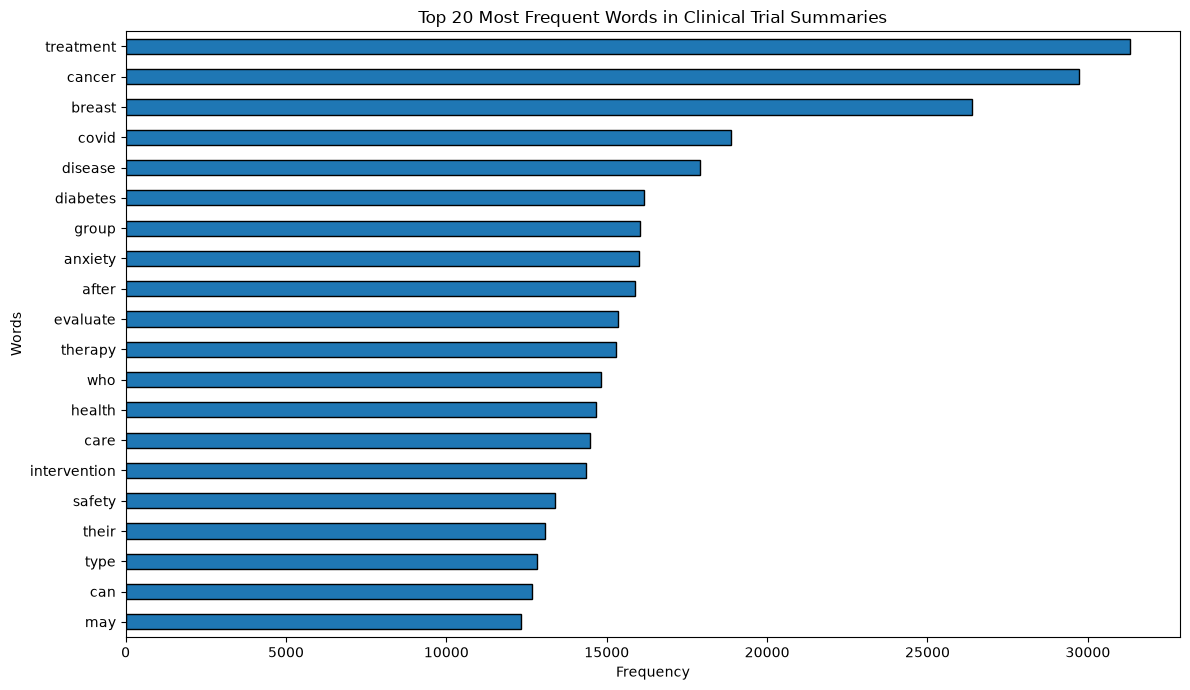

In [24]:
#Top 20 Most Frequent Words Chart

top_words = pd.Series(word_counts).sort_values(ascending=False).head(20)

plt.figure(figsize=(12, 7))

top_words.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 20 Most Frequent Words in Clinical Trial Summaries")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.tight_layout()

plt.savefig(
    os.path.join(CHARTS_PATH, "top_20_frequent_words.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
#Disease Category Percentage Analysis

category_counts = df["source_condition_query"].value_counts()

category_percentages = (
    df["source_condition_query"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

category_summary = pd.DataFrame({
    "Trial_Count": category_counts,
    "Percentage": category_percentages
})

print("Disease Category Analysis:")
print(category_summary)

print("\nTotal Clinical Trials:", category_summary["Trial_Count"].sum())
print("Total Categories:", len(category_summary))
print("Total Percentage:", category_summary["Percentage"].sum())

Disease Category Analysis:
                                       Trial_Count  Percentage
source_condition_query                                        
breast cancer                                16301       27.02
type 2 diabetes                              11467       19.00
covid-19                                     10153       16.83
anxiety                                       9286       15.39
chronic obstructive pulmonary disease         6181       10.24
rheumatoid arthritis                          3637        6.03
glaucoma                                      2173        3.60
sickle cell anemia                            1139        1.89

Total Clinical Trials: 60337
Total Categories: 8
Total Percentage: 100.0


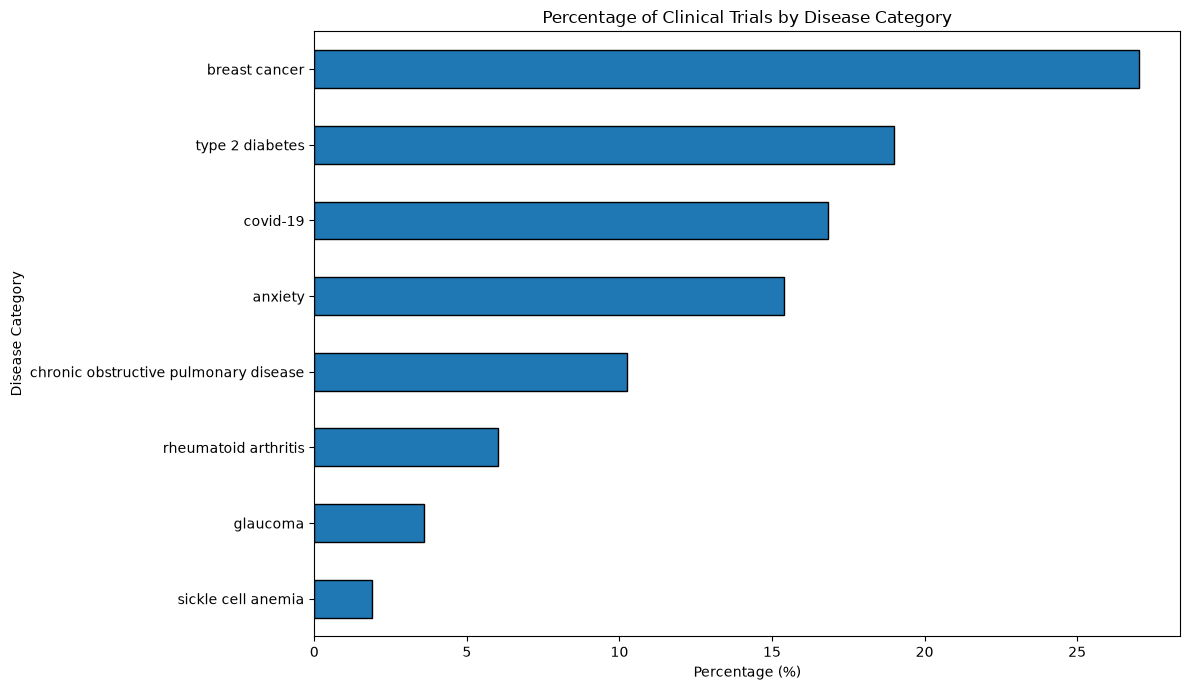

In [26]:
#Disease Category Percentage Chart

plt.figure(figsize=(12, 7))

category_summary["Percentage"].sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Percentage of Clinical Trials by Disease Category")
plt.xlabel("Percentage (%)")
plt.ylabel("Disease Category")

plt.tight_layout()

plt.savefig(
    os.path.join(CHARTS_PATH, "disease_category_percentage.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
#Summary Length by Disease Category

summary_length_analysis = (
    df.groupby("source_condition_query")["summary_length"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print("Summary Length Statistics by Disease Category:")
print(summary_length_analysis)

Summary Length Statistics by Disease Category:
                                       count    mean  median  min   max
source_condition_query                                                 
anxiety                                 9286  827.50   633.0   24  4980
sickle cell anemia                      1139  783.92   544.0   36  3829
covid-19                               10153  751.89   522.0   24  4997
chronic obstructive pulmonary disease   6181  701.35   475.0   20  4978
type 2 diabetes                        11467  641.85   413.0   17  5011
breast cancer                          16301  639.84   442.0   29  5005
rheumatoid arthritis                    3637  568.15   361.0   27  4922
glaucoma                                2173  518.79   304.0   28  4888


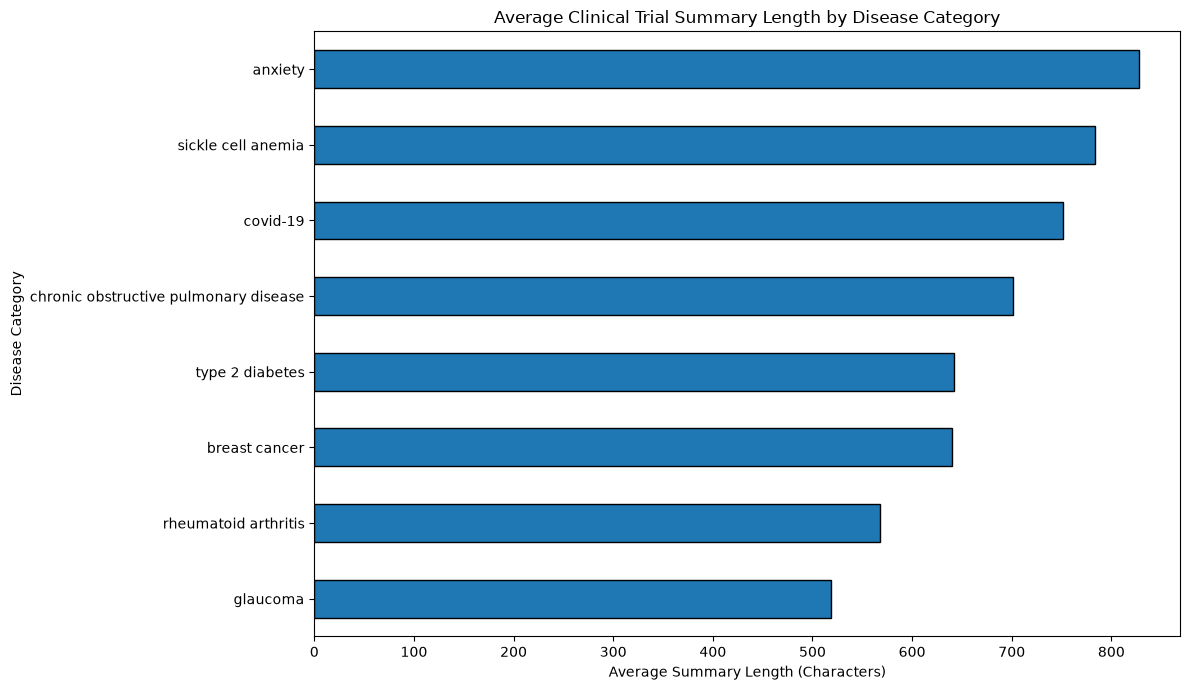

In [28]:
#Summary Length Comparison Chart

plt.figure(figsize=(12, 7))

summary_length_analysis["mean"].sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Average Clinical Trial Summary Length by Disease Category")
plt.xlabel("Average Summary Length (Characters)")
plt.ylabel("Disease Category")

plt.tight_layout()

plt.savefig(
    os.path.join(CHARTS_PATH, "summary_length_by_category.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
#Top Words by Disease Category

disease_categories = df["source_condition_query"].unique()

for category in disease_categories:
    category_text = " ".join(
        df.loc[df["source_condition_query"] == category, "brief_summary"]
    ).lower()

    words = re.findall(r"\b[a-zA-Z]+\b", category_text)

    filtered_words = [
        word for word in words
        if word not in stop_words and len(word) > 2
    ]

    word_frequency = Counter(filtered_words)

    print("\nDisease Category:", category)
    print(pd.Series(word_frequency).sort_values(ascending=False).head(10))


Disease Category: breast cancer
cancer          27811
breast          26236
treatment       10602
therapy          6402
chemotherapy     6235
tumor            5888
women            5708
may              5010
after            4755
phase            4599
dtype: int64

Disease Category: covid-19
covid          18716
sars            5827
cov             5385
infection       4366
disease         4014
treatment       3497
health          3455
care            3421
who             3240
respiratory     3188
dtype: int64

Disease Category: chronic obstructive pulmonary disease
copd           9094
disease        4501
chronic        4334
pulmonary      4149
treatment      2959
obstructive    2702
lung           2346
respiratory    1847
exercise       1777
care           1730
dtype: int64

Disease Category: rheumatoid arthritis
arthritis     3155
rheumatoid    2739
treatment     2117
disease       2085
safety        1464
evaluate      1166
efficacy      1119
who            937
activity       900
pu

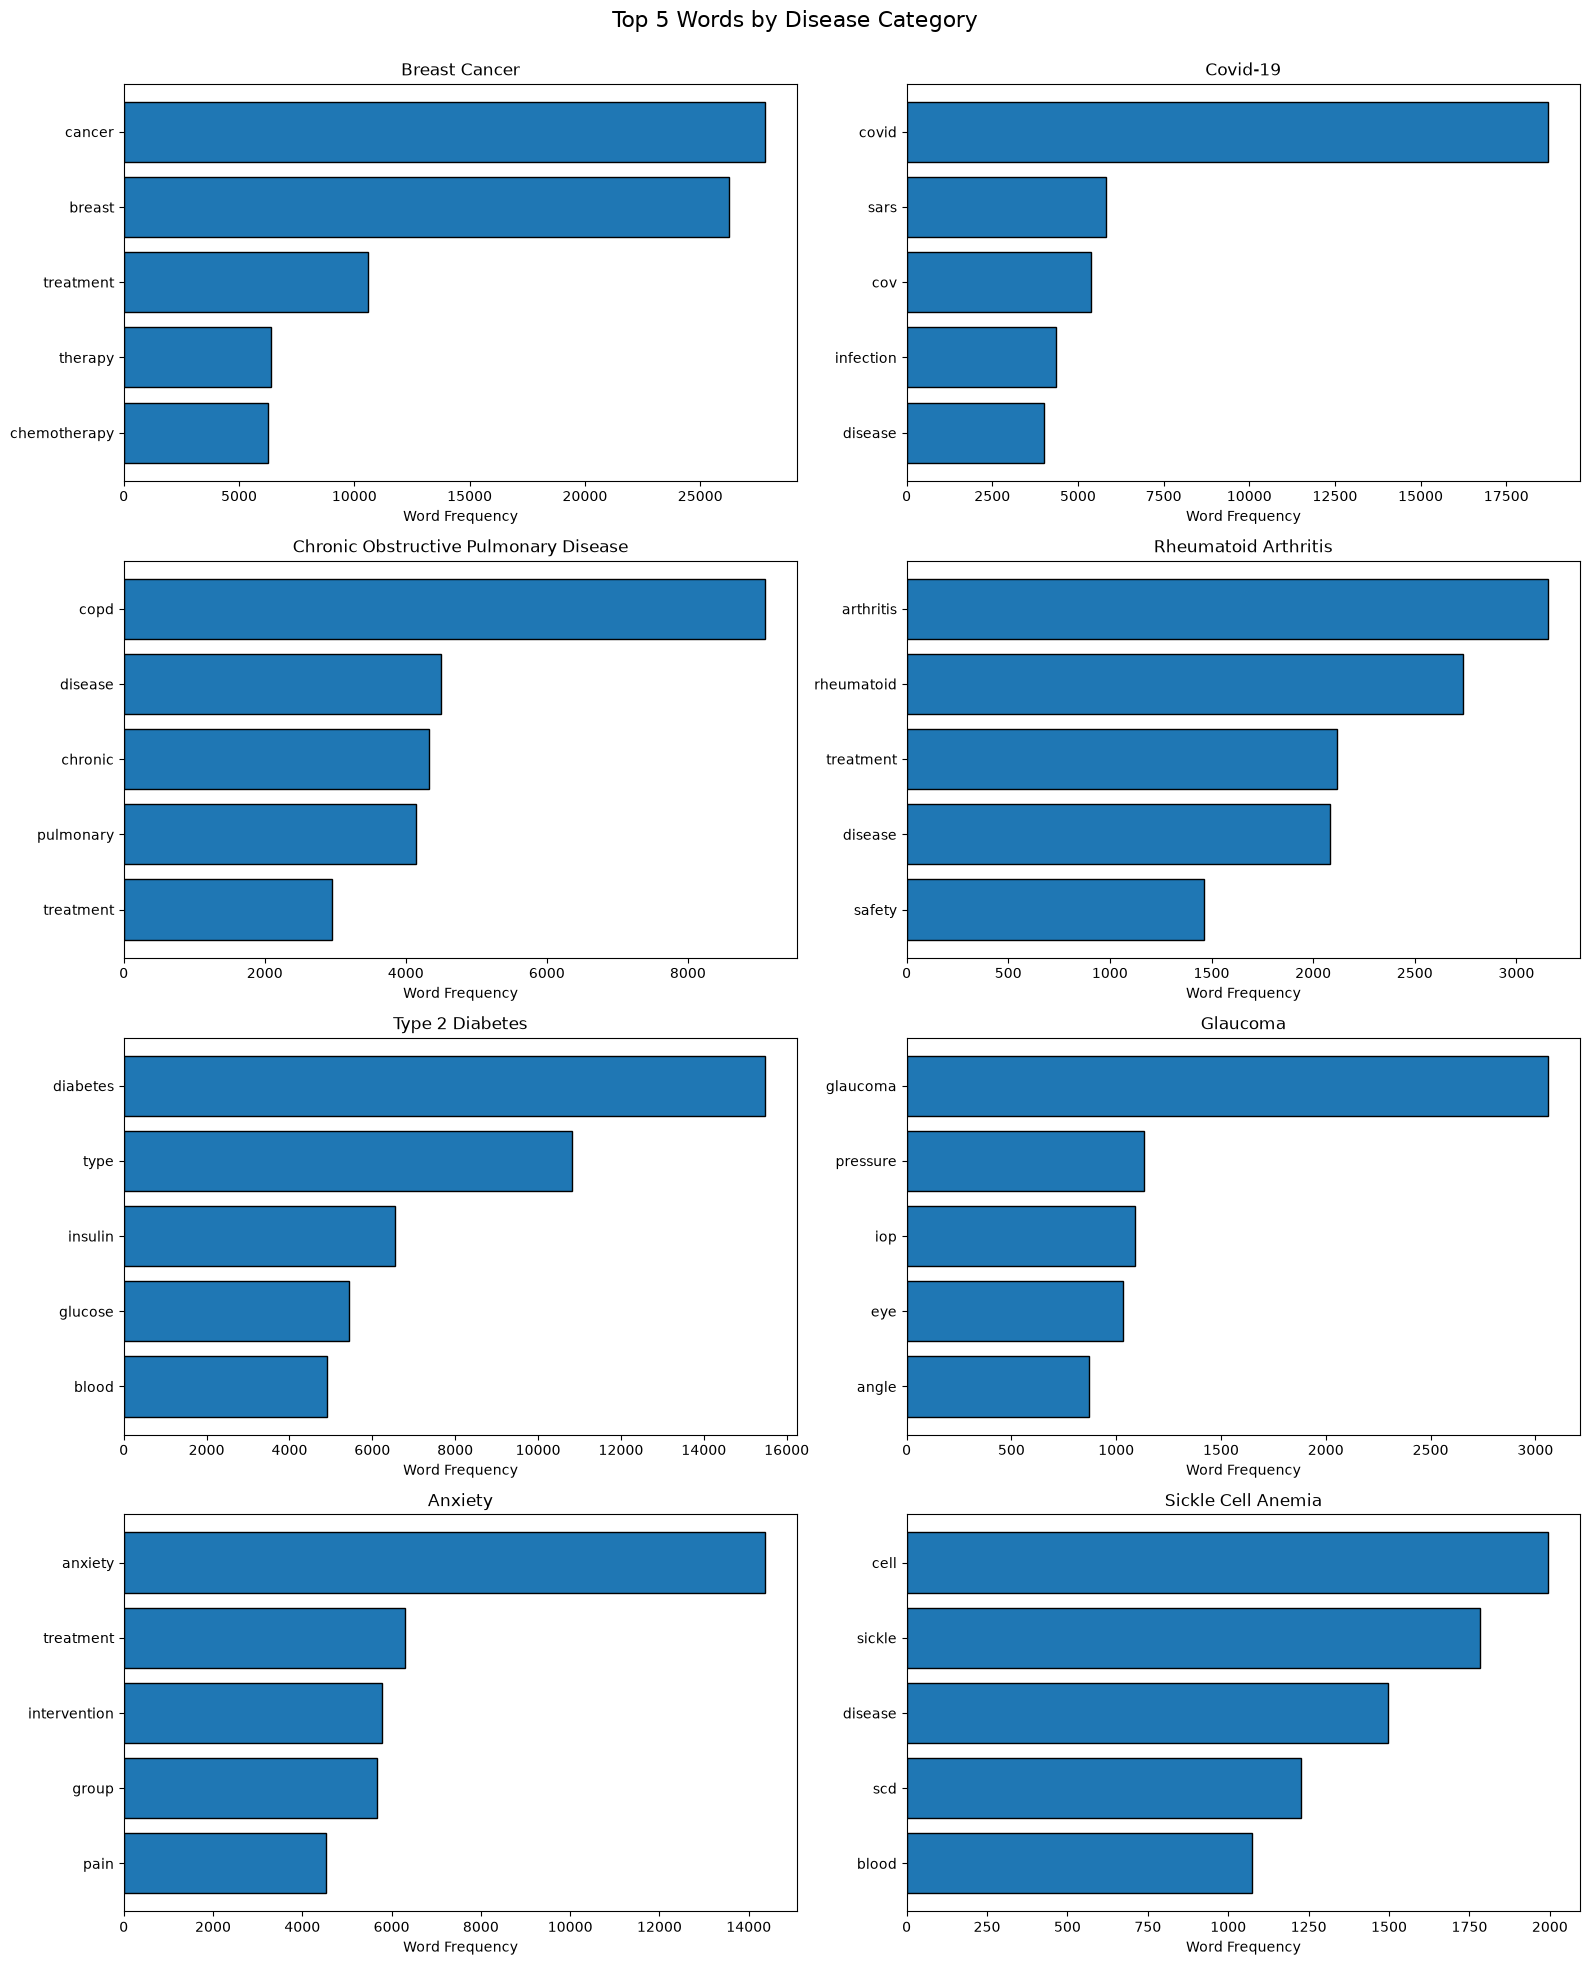

In [30]:
#Top Words by Disease Category Chart

from collections import Counter
import re

top_words_by_category = {}

for category in df["source_condition_query"].unique():
    category_text = " ".join(
        df.loc[
            df["source_condition_query"] == category,
            "brief_summary"
        ]
    ).lower()

    words = re.findall(r"\b[a-zA-Z]+\b", category_text)

    filtered_words = [
        word for word in words
        if word not in stop_words and len(word) > 2
    ]

    top_words_by_category[category] = Counter(filtered_words).most_common(5)

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for ax, (category, words) in zip(axes, top_words_by_category.items()):
    word_labels = [word for word, count in words]
    word_values = [count for word, count in words]

    ax.barh(word_labels[::-1], word_values[::-1], edgecolor="black")
    ax.set_title(category.title())
    ax.set_xlabel("Word Frequency")

plt.suptitle("Top 5 Words by Disease Category", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.98])

plt.savefig(
    os.path.join(CHARTS_PATH, "top_words_by_disease_category.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
#Verify EDA Output Files

print("Charts saved in:", CHARTS_PATH)

chart_files = [
    file for file in os.listdir(CHARTS_PATH)
    if file.endswith(".png")
]

print("\nTotal Charts:", len(chart_files))

for file in sorted(chart_files):
    print(file)

Charts saved in: c:\Users\acer\Documents\Clinical_Trial_Classification\outputs\eda_charts

Total Charts: 6
disease_category_distribution.png
disease_category_percentage.png
summary_length_by_category.png
summary_length_distribution.png
top_20_frequent_words.png
top_words_by_disease_category.png
